In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Part 2: Mean Models {-}

\lhead{Part 2: Mean Models}

\lfoot{Financial Data Science}

\rfoot{\footnotesize Page \thepage\ of \pageref{LastPage}}

\cfoot{Updated \today}

The term **Mean Model** will be used here to refer to a model which, from a probability standpoint, only can be used to characterize how the **expected value** of a modelling random variable depends on unknown parameters and other known quantities.

A mean model is **not** a probability model because it does not fully specify the distribution for the modelling random variables. A mean model is often an important component of a probability model, however.

In its most general form, we will assume that the mean model for observation $i$ in the training set, denoted $Y_i$, can be expressed as
\begin{equation*}
   E(Y_i) = m(\theta, {\bf x}_i)
\end{equation*}
where here $m$ is the mean model, $\theta$ are the unknown parameters, and ${\bf x}_i$ are the known
covariates/predictors/features.

This could also be written as
\begin{equation*}
   Y_i = m(\theta, {\bf x}_i) + \epsilon_i
\end{equation*}
where $\epsilon_i$ is a mean zero random variable.

\newpage

In cases where we have a training set consisting of $({\bf x}_i, y_i)$ pairs,
a popular option for fitting a mean model is via **least squares** where we seek the $\theta$ that minimizes the **residual sum of squares (RSS)**, defined as follows:
\begin{equation*}
   {\rm RSS}(\theta) = \sum_{i=1}^n \left(y_i - m(\theta,{\bf x}_i)\right)^2
\end{equation*}

**Exercise:** What is the motivation behind estimation via least squares?

\answerlines{17}

\newpage

You may hear "least squares" and immediately think of classic linear regression models (and we will consider that case in depth soon). But, it's important to recognize that this framework can be used more generally.

**Exercise:** Suppose that $Y_1, Y_2, \ldots, Y_n$ are iid from some distribution with expected value $\mu$. What is the least squares estimator for $\mu$?

\answerlines{10}

\newpage

## Example: Yield Curve Models {-}

A **yield curve** plots the current interest rates (yields) of bonds with the same credit quality but different maturity dates. It typically illustrates the yields of government bonds across time, ranging from short-term bills to long-term bonds. It can be a key indicator of market expectations regarding the future.

The **Nelson-Siegel model** for the yield curve is as follows:

\begin{equation*}
y(T) = \beta_0 + \beta_1 \!\left( \frac{1 - e^{-T/\tau}}{T/\tau} \right) + \beta_2 \!\left( \frac{1 - e^{-T/\tau}}{T/\tau} - e^{-T/\tau} \right)
\end{equation*}

This is a function of four parameters: $\beta_0$, $\beta_1$, $\beta_2$, and $\tau$.

The Nelson-Siegel model is an example of a mean model since it only describes the curve, not how
the observations will scatter around that curve.

\newpage

The package `neslon-siegel-svensson` implements this model.
The method `NelsonSiegelCurve` returns the yield function based on specified parameter values.
(The parameters are ordered $(\beta_0,\beta_1,\beta_2, \tau)$.)

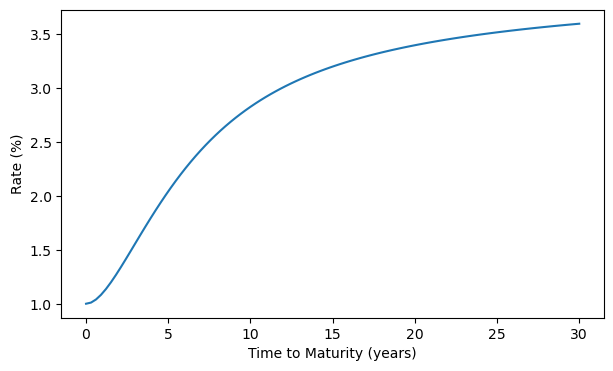

In [2]:
import nelson_siegel_svensson as nss
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np

yld = nss.NelsonSiegelCurve(4.0, -3.0, -3.0, 2)
t = np.linspace(0, 30, 100)
plt.figure(figsize=[7,4])
plt.plot(t, yld(t))
plt.xlabel("Time to Maturity (years)"), plt.ylabel("Rate (%)")
plt.show()

\newpage

The syntax below will scrape data directly from the US Treasury web site. (I am using the "Daily Treasury Par Yield Curve Rates.")

In [3]:
url = "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/2026/all?type=daily_treasury_yield_curve&field_tdr_date_value=2026&page&_format=csv"
YCdata = pd.read_csv(url)

Next convert the date information into a properly defined Python date/time object, and also convert the dates into the indices for the rows.

In [4]:
YCdata['Date'] = YCdata['Date'].astype('datetime64[ns]')
YCdata = YCdata.set_index("Date")

\newpage

Below is a plot of the yield curve for August 10, 2026.

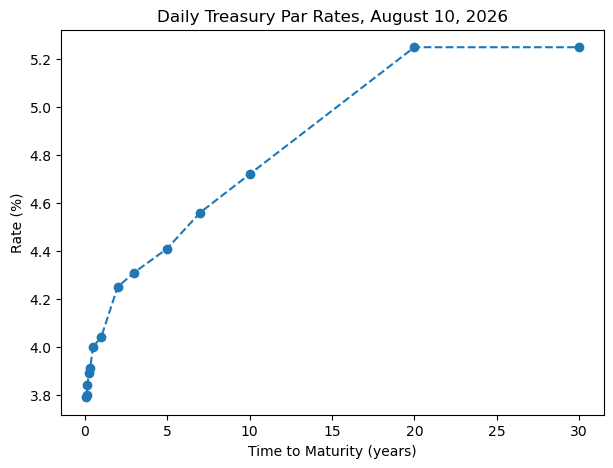

In [5]:
YC081026 = YCdata.loc["2026-08-10"]

maturities = np.array([1/12, 1.5/12, 2/12, 3/12, 4/12,6/12,1,2,3,5,7,10,20,30])
plt.figure(figsize=[7,5])
plt.plot(maturities,YC081026,marker='o', linestyle='--')
plt.xlabel("Time to Maturity (years)")
plt.ylabel("Rate (%)")
plt.title("Daily Treasury Par Rates, August 10, 2026")
plt.show()

\newpage

We can use least squares to fit the Nelson-Siegel model. 

We will demonstrate this using `minimize` from `scipy`.

In [6]:
from scipy.optimize import minimize

Define the function to be minimized. Note that the first argument must be the parameters to be minimized over, passed as a single vector.

In [7]:
def NSleastsquarescrit(NSpars,obsyields,maturities):
    yld = nss.NelsonSiegelCurve(*NSpars)
    return sum((yld(maturities)-obsyields)**2.0)

Now call `minimize`. The second argument is the initial value for the iterative search. The `args` construct allows you to pass arguments on to the function being minimized. (The default approach used by `minimize` for
unconstrained optimization problems is BFGS.)

In [8]:
nsfit = minimize(NSleastsquarescrit,[4,-2,-3,2],args=(YC081026,maturities))

\newpage

Here is the vector of parameters found via least squares, along with a plot of the fit.

In [9]:
nsfit.x

array([ 5.61501807e+00, -1.76492309e+00, -9.72633672e-05,  5.51866591e+00])

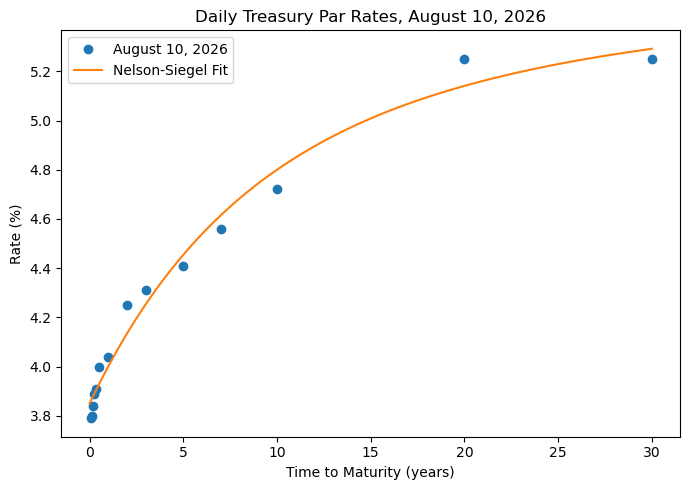

In [10]:
t = np.linspace(0, 30, 100)

curve_ns = nss.NelsonSiegelCurve(*nsfit.x)
plt.figure(figsize=(7, 5))
plt.plot(maturities, YC081026, "o", label="August 10, 2026")
plt.plot(t, curve_ns(t), label="Nelson-Siegel Fit")
plt.xlabel("Time to Maturity (years)")
plt.ylabel("Rate (%)")
plt.legend()
plt.title("Daily Treasury Par Rates, August 10, 2026")
plt.tight_layout()
plt.show()

In fact, the `nelson_siegel_svensson` package actually has the least squares procedure built in:

In [11]:
from nelson_siegel_svensson import calibrate

curve_ns, status = calibrate.calibrate_ns_ols(maturities, YC081026)

\newpage

The Nelson-Siegel-Svensson model includes an additional term, and two more parameters, as follows:
\begin{equation*}
y(T) = \beta_0 + \beta_1 \!\left( \frac{1 - e^{-T/\tau_1}}{T/\tau_1} \right) + 
\beta_2 \!\left( \frac{1 - e^{-T/\tau_1}}{T/\tau_1} - e^{-T/\tau_1} \right) +
\beta_3 \!\left( \frac{1 - e^{-T/\tau_2}}{T/\tau_2} - e^{-T/\tau_2}\right)
\end{equation*}


The Python package can fit this model as follows:

In [12]:
curve_nss, status = calibrate.calibrate_nss_ols(maturities, YC081026)

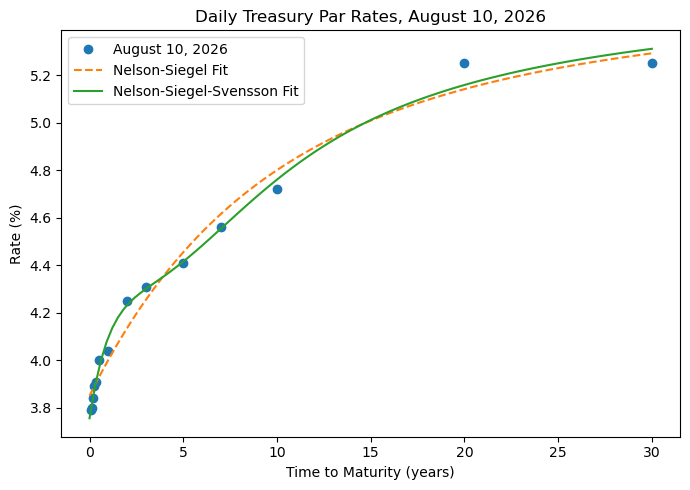

In [13]:
plt.figure(figsize=(7, 5))
plt.plot(maturities, YC081026, "o", label="August 10, 2026")
plt.plot(t, curve_ns(t), label="Nelson-Siegel Fit",linestyle="--")
plt.plot(t, curve_nss(t), label="Nelson-Siegel-Svensson Fit")
plt.xlabel("Time to Maturity (years)")
plt.ylabel("Rate (%)")
plt.legend()
plt.title("Daily Treasury Par Rates, August 10, 2026")
plt.tight_layout()
plt.show()

\newpage

**Exercise:** Comment on the quality of these fits.

\answerlines{10}

\newpage

**Comment:** The "OLS" in these function names stands for **ordinary least squares**. This is contrasted with **weighted least squares** in which weights are attached to each of the terms in the criterion, i.e.,
\begin{equation*}
   {\rm WRSS}(\theta) = \sum_{i=1}^n w_i \!\left(y_i - m(\theta,{\bf x}_i)\right)^2.
\end{equation*}

Introducing weights can be crucial in situations where some observations are known to be subject to much larger errors than others (referred to as **heteroskedasticity**). For example, in cases when fitting models using options data, prices corresponding to
heavily-traded options are much more reliable than their lightly-traded counterparts.

\newpage

## Example: Calibrating Options Models {-}

The **Black-Scholes model** is used to calculate the theoretical fair value of European-style options.

The model makes some simplifying assumptions (as they all do) that can limit its usefulness, but it still plays an important role in many situations, in part because of its simplicity.

There are five inputs into the B-S model:

1. Spot Price ($S$): The current market price of the underlying asset.
2. Strike Price ($K$): The predetermined price at which the option can be bought or sold upon exercise.
3. Time to Expiration ($T$): The time remaining until the option contract expires, expressed as an annualized fraction (e.g., 6 months = 0.5).
4. Risk-Free Interest Rate ($r$): The constant, annualized rate of return for a risk-free investment (like a government bond) over the lifespan of the option.
5. Volatility ($\sigma$): The annualized standard deviation of the underlying asset's continuously compounded returns.

\newpage

Volatility is the one of these five is not directly observable or easily estimated. A common approach is to ask: What value for $\sigma$ makes the B-S price align with the current market price for the option? The answer is called the **implied volatility**.

As a result, there is a one-to-one relationship between market price and implied vol, and it is common to see implied vol reported instead of market price. Here we will explore why this is a useful approach, in the context of fitting mean models using least squares.

Under the B-S model, volatility is a fixed constant. If this were true, all options on the same underlying asset with the same expiration date should have equal implied volatility, regardless of their strike price.

However, real markets exhibit a **volatility smile** or **volatility skew**. 

Models such as the **Heston model** incorporate **stochastic volatility** and will model the volatility smile. The Heston model has five parameters that must be calibrated to the observed data.

\newpage

We will illustrate the volatility smile using options on the S&P 500. In `yfinance` these can be obtained using the ticker symbol `^SPX`.

In [14]:
SPX = yf.Ticker('^SPX')

Pick out one expiration date and obtain the call option chain.

In [35]:
from datetime import date,datetime

targetdate = SPX.options[10]
print(f"Using call options with expiration {targetdate}")

calls = SPX.option_chain(targetdate).calls

time_to_expiry = (datetime.fromisoformat(targetdate).date() - date.today()).days/365.25

Using call options with expiration 2026-09-10


This is an approximation to the most recent value of `SPX`.

In [36]:
currentprice = SPX.history()['Close'].iloc[-1]

Remove options that have not traded today.

In [37]:
calls = calls[calls['lastTradeDate'].dt.date == date.today()]

A standard function for calculating implied vol is in `vollib`.

In [38]:
from vollib.black_scholes.implied_volatility import implied_volatility

calls['iv'] = calls.apply(
    lambda row: implied_volatility(
        row['lastPrice'], currentprice, 
        row['strike'], time_to_expiry, 
        0.04, 'c'
    ), axis=1
)

\newpage

Finally, plot the smile.

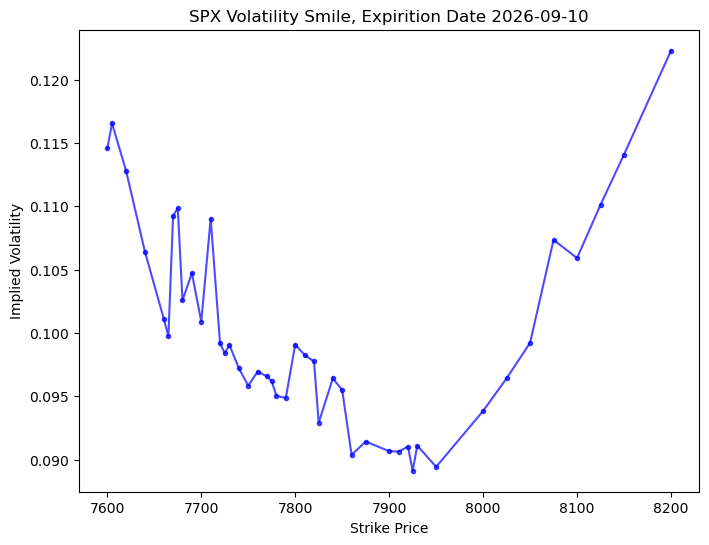

In [39]:
plt.figure(figsize=(8, 6))
plt.plot(calls['strike'], calls['iv'], 'b.-', alpha=0.7)

plt.title(f'SPX Volatility Smile, Expirition Date {targetdate}')
plt.xlabel('Strike Price')
plt.ylabel('Implied Volatility')
plt.show()

\newpage

Compare this with the market price as a function of strike.

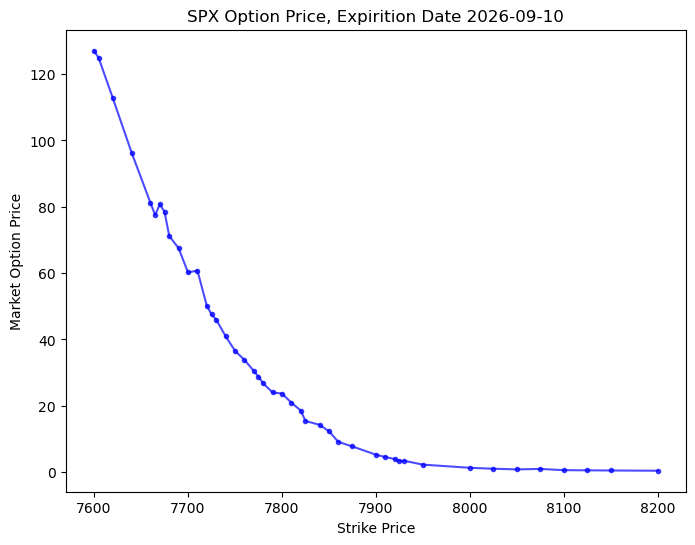

In [34]:
plt.figure(figsize=(8, 6))
plt.plot(calls['strike'], calls['lastPrice'], 'b.-', alpha=0.7)

plt.title(f'SPX Option Price, Expirition Date {targetdate}')
plt.xlabel('Strike Price')
plt.ylabel('Market Option Price')
plt.show()

\newpage

**Exercise:** Why would it be a good idea to calibrate a model to the implied vol surface instead of to the actual prices?

\answerlines{20}

\newpage

**Exercise:** How/why should weighted least squares be used in this case?
    
\answerlines{20}